# 09 · The evaluation

The agent and two simpler systems audited the 400 exam listings, which nothing was tuned
on. This notebook reads what the runs saved under `results/exam/` and looks at the
results: what each system caught and missed, where it raised false alarms, the numbers it
made up, whether its fixes work, how the AI judge's grades compare with a person's, and
what it costs.

It needs neither the database nor a language model.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from listingaudit.agent.selfcheck import amounts
from listingaudit.eval import grade as grader
from listingaudit.eval.records import folder, read_json_lines, read_records, records_path

SPLIT = "exam"
scores, listings = grader.load(SPLIT)
systems = [system for system in grader.SYSTEMS if system in scores]
print(f"{listings} listings; results for: {', '.join(systems)}")

Matplotlib is building the font cache; this may take a moment.


400 listings; results for: agent, rules_only, one_prompt


## The results table

The same table as in the README. "Agent meets it" compares the agent with the target
from the project plan.

In [2]:
display(Markdown(grader.headline(scores)))

| Question | agent | rules only | one prompt | Target | Agent meets it |
|---|---|---|---|---|---|
| Catches price problems | 100% (90/90) | 100% (90/90) | 100% (75/75) | 90% | yes |
| Catches missing information and label problems | 92% (112/122) | 92% (112/122) | 96% (101/105) | 90% | yes |
| Catches photo swaps | 77% (23/30) | 0% (0/30) | 100% (28/28) | 70% | yes |
| Clean listings with a false alarm | 4% (4/104) | 0% (0/105) | 57% (54/94) | under 5% | yes |
| Tricky but legal listings with a false alarm | 9% (7/75) | 9% (7/75) | 68% (45/66) |  |  |
| Possible problems that are real (precision) | 93% (225/242) | 97% (202/209) | 50% (204/408) |  |  |
| Listings checked against exactly the right rules | 95% (381/399) | 96% (385/400) | n/a | 90% | yes |
| Findings quoting the rule's own law and article | 36% (88/242) | n/a | 66% (271/408) | 95% | no |
| Reports with only real numbers | 100% (399/399) | 100% (400/400) | 68% (237/349) | 100% | yes |
| Fixes that pass the check once applied | 67% (135/202) | n/a | 82% (144/176) | 95% | no |
| Clarity / fairness, judged by a model (1 to 5) | 4.34 / 4.75 | n/a | 1.86 / 2.22 |  |  |
| Judge within one point of a person's grade | n/a | n/a | n/a | most |  |
| Sneaky-note listings with every problem still found | 100% (20/20) | 100% (20/20) | 94% (15/16) | 100% | yes |
| Listings with the same findings in every run | 90% (9/10) | n/a | n/a | most | yes |
| Cost per 1,000 listings (USD, list price) | $3.15 | $0.00 | $2.34 |  |  |
| Minutes per 1,000 listings, one at a time | 165 | 0 | 196 |  |  |

## Problems caught, by group

The share of planted problems each system reported, in the three groups of the table.

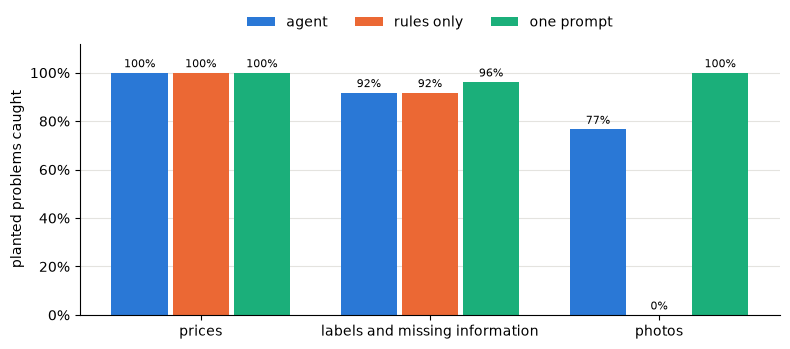

In [3]:
COLOURS = {"agent": "#2a78d6", "rules_only": "#eb6834", "one_prompt": "#1baf7a"}
groups = list(grader.GROUPS)
width = 0.8 / len(systems)

fig, ax = plt.subplots(figsize=(8, 3.6))
for n, system in enumerate(systems):
    shares = [
        hits / total if total else 0
        for hits, total in (scores[system].caught.get(group, (0, 0)) for group in groups)
    ]
    x = [i + (n - (len(systems) - 1) / 2) * width for i in range(len(groups))]
    bars = ax.bar(x, shares, width * 0.92, color=COLOURS[system], label=system.replace("_", " "))
    ax.bar_label(bars, labels=[f"{share:.0%}" for share in shares], fontsize=8, padding=2)
ax.set_xticks(range(len(groups)), groups)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.set_ylabel("planted problems caught")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncols=len(systems), loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout()
plt.show()

## By kind of problem and by trap

Each planted problem comes in an easy and a hard version. The traps are legal listings
that look wrong; a flag on the trap's rule is a false alarm.

In [4]:
display(Markdown(grader.details(scores)))

Planted problems caught

| Planted problem, difficulty | agent | rules_only | one_prompt |
|---|---|---|---|
| bad_fibre_composition, easy | 100% (11/11) | 100% (11/11) | 75% (6/8) |
| bad_fibre_composition, hard | 100% (11/11) | 100% (11/11) | 100% (8/8) |
| bad_unit_price, easy | 100% (15/15) | 100% (15/15) | 100% (14/14) |
| bad_unit_price, hard | 100% (15/15) | 100% (15/15) | 100% (15/15) |
| missing_energy_label, easy | 100% (10/10) | 100% (10/10) | 100% (8/8) |
| missing_energy_label, hard | 100% (10/10) | 100% (10/10) | 100% (10/10) |
| missing_eu_responsible_person, easy | 100% (15/15) | 100% (15/15) | 100% (11/11) |
| missing_eu_responsible_person, hard | 100% (15/15) | 100% (15/15) | 100% (15/15) |
| missing_manufacturer_info, easy | 100% (15/15) | 100% (15/15) | 100% (12/12) |
| missing_manufacturer_info, hard | 100% (15/15) | 100% (15/15) | 100% (15/15) |
| missing_safety_warnings, easy | 100% (10/10) | 100% (10/10) | 100% (9/9) |
| missing_safety_warnings, hard | 0% (0/10) | 0% (0/10) | 78% (7/9) |
| photo_mismatch, easy | 80% (12/15) | 0% (0/15) | 100% (15/15) |
| photo_mismatch, hard | 73% (11/15) | 0% (0/15) | 100% (13/13) |
| pumped_price, easy | 100% (15/15) | 100% (15/15) | 100% (13/13) |
| pumped_price, hard | 100% (15/15) | 100% (15/15) | 100% (12/12) |
| sneaky_percentage, easy | 100% (15/15) | 100% (15/15) | 100% (10/10) |
| sneaky_percentage, hard | 100% (15/15) | 100% (15/15) | 100% (11/11) |

False alarms on tricky listings

| Trap (legal), flagged as a problem | agent | rules_only | one_prompt |
|---|---|---|---|
| eu_maker_no_rp_needed | 0% (0/10) | 0% (0/10) | 0% (0/9) |
| exact_kilo_or_litre | 0% (0/1) | 0% (0/1) | 100% (1/1) |
| lamp_no_energy_label | 20% (2/10) | 0% (0/10) | 44% (4/9) |
| long_price_rise | 0% (0/10) | 0% (0/10) | 20% (2/10) |
| mixed_set | 0% (0/8) | 0% (0/8) | 71% (5/7) |
| not_a_textile | 0% (0/7) | 100% (7/7) | 0% (0/6) |
| rrp_comparison | 0% (0/10) | 0% (0/10) | 0% (0/9) |
| sale_started_earlier | 0% (0/10) | 0% (0/10) | 38% (3/8) |
| sold_by_piece | 0% (0/3) | 0% (0/3) | 33% (1/3) |
| unannounced_price_drop | 0% (0/6) | 0% (0/6) | 0% (0/4) |

## Numbers no check worked out

Every price and percentage in a report should come from a check's result or the listing
itself. These are the ones that didn't, with the sentence they appear in.

In [5]:
def made_up_sentences(system, limit=5):
    shown = 0
    for record in read_records(records_path(SPLIT, system)):
        if record.repeat or record.error:
            continue
        prefix = f"{record.offer_id}: "
        extra = [
            item.removeprefix(prefix) for item in scores[system].made_up if item.startswith(prefix)
        ]
        if not extra:
            continue
        for text in grader.model_text(record.report):
            if set(extra) & {str(amount) for amount in amounts(text)}:
                print(f"{record.offer_id}: {text}")
                shown += 1
                break
        if shown == limit:
            return


for system in systems:
    made_up = scores[system].made_up
    print(f"--- {system}: {len(made_up)} made-up numbers in {scores[system].audited} reports")
    made_up_sentences(system)

--- agent: 0 made-up numbers in 399 reports
--- rules_only: 0 made-up numbers in 400 reports
--- one_prompt: 235 made-up numbers in 349 reports
E0002: The crossed‑out previous price is €327.99 and the current price is €278.99. The percentage badge shown is 14%, but the reduction from €327.99 to €278.99 is €49.00, i.e. 49.00/327.99 ≈ 14.94%, which should be rounded/represented as ≈15%, not 14%. Recalculate and display the discount percentage from the lowest price in the 30 days before the sale started (here €327.99); show the percentage as approximately 15% (or use the marketplace’s rounding rule but ensure it reflects 49/327.99).
E0006: The price fell from €50.99 to €40.99 on 2026-11-02. The lowest price in the 30 days before that reduction (2026-10-03 to 2026-11-01) was €50.99, so the crossed-out was-price is correct, but the displayed discount 19% is not: (50.99−40.99)/50.99 = 0.1961 ≈ 19.61%, which rounds to 20%, not 19%. Recalculate and display the discount percentage from €50.99 (

## Do the fixes work?

Each suggested fix for a real problem was applied to its listing by a model, taking every
number from the fix's own words, and the rule's check ran again. "vague" means the fix
left a number to the seller; "cannot_check" fixes (a new photo) aren't counted.

In [6]:
fixes = read_json_lines(folder(SPLIT) / "fixes.jsonl")
if fixes:
    table = pd.crosstab(
        pd.Series([row["system"] for row in fixes], name="system"),
        pd.Series([row["outcome"] for row in fixes], name="outcome"),
    )
    display(table)
    failed = [row for row in fixes if row["system"] == "agent" and row["outcome"] != "pass"]
    for row in failed[:5]:
        print(f"{row['offer_id']} {row['rule']} ({row['outcome']}): {row['fix']}")
        print(f"    {row['detail']}")
else:
    print("No fix results yet: run python -m listingaudit.eval.fixes")

outcome,fail,invalid,pass,vague
system,,,,
agent,12,38,135,17
one_prompt,3,24,144,5


E0005 unit_price (invalid): Display the Grundpreis (unit price) clearly and legibly alongside the Gesamtpreis, for example showing “€9.50 per l” next to the €3.99 price for the 420 ml product.
    Input should be 'kg', 'l', '100 g' or '100 ml'
E0016 unit_price (invalid): Display the unit price clearly and legibly next to the total price, for example: “€23.43 per l” alongside the €16.99 selling price for the 725 ml product.
    Value error, a unit price needs its unit, and only then
E0020 prior_price (fail): Use the actual lowest price charged during the 30 days before the reduction (€45.99) as the prior price and update the crossed-out price and the -33% badge to show the correct percentage based on that prior price, or provide a documented, permitted exception and clear explanation if one applies.
    The badge says -33%, but the price is only 6.5% below €45.99, the lowest price of the 30 days before the sale.
E0023 energy_label (invalid): Display the product's energy efficiency class

## The AI judge against a person

The judge (DeepEval's G-Eval) graded every report with a possible problem; a person
graded 30 of the agent's reports without seeing the judge's grades. Each cell counts the
reports with that pair of grades; the diagonal is full agreement.

In [7]:
rows = read_json_lines(folder(SPLIT) / "judge.jsonl")
judged = {row["offer_id"]: row for row in rows if row["system"] == "agent"}
human_path = folder(SPLIT) / "human_grades.csv"
people = pd.read_csv(human_path, dtype={"offer_id": str}) if human_path.exists() else pd.DataFrame()
both = people[people["offer_id"].isin(judged)] if len(people) else people
if len(both):
    for criterion in ("clarity", "fairness"):
        judge_grades = [judged[offer_id][criterion] for offer_id in both["offer_id"]]
        display(Markdown(f"**{criterion.title()}**"))
        display(
            pd.crosstab(
                both[criterion].rename("person"), pd.Series(judge_grades, both.index, name="judge")
            )
        )
    notes = both[both["note"].notna() & (both["note"] != "")]
    for _, row in notes.iterrows():
        reason = judged[row["offer_id"]]["clarity_reason"]
        print(f"{row['offer_id']}: person: {row['note']} | judge: {reason}")
else:
    print("No grades from both the judge and a person yet.")

No grades from both the judge and a person yet.


## Same answer twice?

Ten listings were audited five times by the agent. A listing is consistent when every run
flagged the same rules.

In [8]:
runs = {}
for record in read_records(records_path(SPLIT, "agent")):
    if not record.error:
        runs.setdefault(record.offer_id, []).append(sorted(grader.flagged(record)))
repeated = {offer: found for offer, found in runs.items() if len(found) > 1}
if repeated:
    for offer, found in repeated.items():
        changes = Counter(", ".join(rules) or "nothing" for rules in found)
        print(f"{offer}: " + "; ".join(f"{rules} x{n}" for rules, n in changes.items()))
else:
    print("No repeated runs yet: run python -m listingaudit.eval.run agent --repeats 5 --sample 10")

E0013: nothing x5
E0058: nothing x5
E0115: nothing x5
E0141: energy_label x5
E0053: prior_price x5
E0072: nothing x3; photo_matches_text x2
E0126: prior_price x5
E0328: nothing x5
E0378: unit_price x5
E0380: energy_label x5


## Cost and time

Tokens at the list price, plus the vision model for the photos CLIP couldn't settle.
The time is per listing, one at a time; runs at the same time finish sooner.

In [9]:
rows = []
for system in systems:
    records = [r for r in read_records(records_path(SPLIT, system)) if not r.repeat and not r.error]
    tokens = Counter()
    for record in records:
        for used in record.tokens.values():
            tokens.update(used)
    audits = max(len(records), 1)
    rows.append(
        {
            "system": system,
            "audits": len(records),
            "input tokens per audit": round(tokens["input_tokens"] / audits),
            "output tokens per audit": round(tokens["output_tokens"] / audits),
            "USD per 1,000": scores[system].usd_per_1000,
            "minutes per 1,000": scores[system].minutes_per_1000,
        }
    )
pd.DataFrame(rows).set_index("system")

,audits,input tokens per audit,output tokens per audit,"USD per 1,000","minutes per 1,000"
system,,,,,
agent,399,6678,702,3.15,164.6
rules_only,400,0,0,0.00,0.0
one_prompt,349,3427,740,2.34,195.9
